# EazyDiner Restaurant Analysis

## Project Objective

To collect restaurant data from EazyDiner using Requests and BeautifulSoup, clean and transform the scraped data using Pandas and Regular Expressions, perform Exploratory Data Analysis (EDA), compare restaurants across different cities, and generate business insights and recommendations based on the analysis.

In [1]:
import requests

In [2]:
url = "https://www.eazydiner.com/vijayawada/restaurants"

In [3]:
response = requests.get(url)

In [4]:
response.status_code

200

In [ ]:
response.text[:500]

'<!DOCTYPE html><html lang="en"><head><meta charSet="utf-8" data-next-head=""/><meta name="viewport" content="width=device-width, initial-scale=1.0, maximum-scale=1.0, user-scalable=0, viewport-fit=cover" data-next-head=""/><link rel="alternate" href="https://www.eazydiner.com/vijayawada/restaurants" hrefLang="en-in" data-next-head=""/><link rel="alternate" href="https://www.eazydiner.com/vijayawada/restaurants" hrefLang="x-default" data-next-head=""/><link rel="icon" type="image/png" href="/imag'

In [6]:
from bs4 import BeautifulSoup

In [7]:
soup = BeautifulSoup(response.text, "html.parser")

In [8]:
"United Food Palace" in response.text

True

In [9]:
soup.find("a", attrs={"aria-label": "United Food Palace"})

<a aria-label="United Food Palace" class="absolute top-0 left-0 right-0 bottom-0" href="https://www.eazydiner.com/vijayawada/united-food-palace-benz-circle-vijayawada-692414"></a>

In [10]:
restaurant = soup.find("a", attrs={"aria-label": "United Food Palace"})
restaurant.get("href")

'https://www.eazydiner.com/vijayawada/united-food-palace-benz-circle-vijayawada-692414'

In [11]:
restaurant.get("aria-label")

'United Food Palace'

In [12]:
restaurant.parent

<div class="relative pointer"><a aria-label="United Food Palace" class="absolute top-0 left-0 right-0 bottom-0" href="https://www.eazydiner.com/vijayawada/united-food-palace-benz-circle-vijayawada-692414"></a><div class="relative pointer" style="pointer-events:none"><div class="relative listing-module__chvBCG__image_container"><div class="flex full-width listing-module__chvBCG__image_main"><div class="flex full_image listing-module__chvBCG__image_internal"><span style="box-sizing:border-box;display:inline-block;overflow:hidden;width:initial;height:initial;background:none;opacity:1;border:0;margin:0;padding:0;position:relative;max-width:100%"><span style="box-sizing:border-box;display:block;width:initial;height:initial;background:none;opacity:1;border:0;margin:0;padding:0;max-width:100%"><img alt="" aria-hidden="true" src="data:image/svg+xml,%3csvg%20xmlns=%27http://www.w3.org/2000/svg%27%20version=%271.1%27%20width=%27343%27%20height=%27240%27/%3e" style="display:block;max-width:100%;w

In [13]:
restaurant.parent.prettify()

'<div class="relative pointer">\n <a aria-label="United Food Palace" class="absolute top-0 left-0 right-0 bottom-0" href="https://www.eazydiner.com/vijayawada/united-food-palace-benz-circle-vijayawada-692414">\n </a>\n <div class="relative pointer" style="pointer-events:none">\n  <div class="relative listing-module__chvBCG__image_container">\n   <div class="flex full-width listing-module__chvBCG__image_main">\n    <div class="flex full_image listing-module__chvBCG__image_internal">\n     <span style="box-sizing:border-box;display:inline-block;overflow:hidden;width:initial;height:initial;background:none;opacity:1;border:0;margin:0;padding:0;position:relative;max-width:100%">\n      <span style="box-sizing:border-box;display:block;width:initial;height:initial;background:none;opacity:1;border:0;margin:0;padding:0;max-width:100%">\n       <img alt="" aria-hidden="true" src="data:image/svg+xml,%3csvg%20xmlns=%27http://www.w3.org/2000/svg%27%20version=%271.1%27%20width=%27343%27%20height=%27

In [15]:
restaurant.parent.find("h3")

<h3 class="margin-0-auto all_unset">United Food Palace</h3>

In [16]:
restaurant.parent.find("h3").get_text(strip=True)

'United Food Palace'

In [ ]:
restaurant.parent.find_all("div", class_="relative font-16 grey ellipsis listing-module__chvBCG__lh_18")

[<div class="relative font-16 grey ellipsis listing-module__chvBCG__lh_18">Benz Circle, Vijayawada</div>,
 <div class="relative font-16 grey ellipsis listing-module__chvBCG__lh_18" title="Chinese, Mughlai, North Indian, Kebabs, Andhra, Biryani">Chinese, Mughlai, North Indian, Kebabs, Andhra, Biryani</div>,
 <div class="relative font-16 grey ellipsis listing-module__chvBCG__lh_18">₹800 for two</div>]

In [18]:
restaurant.parent.find_all("div", class_="relative font-16 grey ellipsis listing-module__chvBCG__lh_18")[0].get_text(strip=True)

'Benz Circle, Vijayawada'

In [19]:
restaurant.parent.find_all("div", class_="relative font-16 grey ellipsis listing-module__chvBCG__lh_18")[1].get_text(strip=True)

'Chinese, Mughlai, North Indian, Kebabs, Andhra, Biryani'

In [20]:
restaurant.parent.find_all("div", class_="relative font-16 grey ellipsis listing-module__chvBCG__lh_18")[2].get_text(strip=True)

'₹800 for two'

In [21]:
restaurant.parent.find("text").get_text(strip=True)

'%'

In [22]:
restaurant.parent.find_all("text")[1].get_text(strip=True)

'3.7'

In [23]:
restaurant.parent.find("div", class_="relative font-16 bold white nowrap ellipsis").get_text(strip=True)

'25% Off :Payeazy'

In [24]:
len(soup.select('a[aria-label]'))

8

In [25]:
[a.get("aria-label") for a in soup.select('a[aria-label]')]

['United Food Palace',
 'Amma Aathidyam',
 'Swagramam Restaurant',
 'Sattvik Soul',
 'Patthar Ka Barbeque',
 'Thrayam Fine Dining Restaurant',
 'Cicely Cafe',
 'RR Durbar']

In [26]:
restaurants = soup.select('a[aria-label]')
restaurants[0].parent

<div class="relative pointer"><a aria-label="United Food Palace" class="absolute top-0 left-0 right-0 bottom-0" href="https://www.eazydiner.com/vijayawada/united-food-palace-benz-circle-vijayawada-692414"></a><div class="relative pointer" style="pointer-events:none"><div class="relative listing-module__chvBCG__image_container"><div class="flex full-width listing-module__chvBCG__image_main"><div class="flex full_image listing-module__chvBCG__image_internal"><span style="box-sizing:border-box;display:inline-block;overflow:hidden;width:initial;height:initial;background:none;opacity:1;border:0;margin:0;padding:0;position:relative;max-width:100%"><span style="box-sizing:border-box;display:block;width:initial;height:initial;background:none;opacity:1;border:0;margin:0;padding:0;max-width:100%"><img alt="" aria-hidden="true" src="data:image/svg+xml,%3csvg%20xmlns=%27http://www.w3.org/2000/svg%27%20version=%271.1%27%20width=%27343%27%20height=%27240%27/%3e" style="display:block;max-width:100%;w

In [27]:
card = restaurants[0].parent

In [28]:
card.find("h3").get_text(strip=True)

'United Food Palace'

In [29]:
card.find_all("div", class_="relative font-16 grey ellipsis listing-module__chvBCG__lh_18")[0].get_text(strip=True)

'Benz Circle, Vijayawada'

In [30]:
card.find_all("div", class_="relative font-16 grey ellipsis listing-module__chvBCG__lh_18")[1].get_text(strip=True)

'Chinese, Mughlai, North Indian, Kebabs, Andhra, Biryani'

In [31]:
cards = [restaurant.parent for restaurant in restaurants]

In [32]:
[card.find("h3").get_text(strip=True) for card in cards]

['United Food Palace',
 'Amma Aathidyam',
 'Swagramam Restaurant',
 'Sattvik Soul',
 'Patthar Ka Barbeque',
 'Thrayam Fine Dining Restaurant',
 'Cicely Cafe',
 'RR Durbar']

In [33]:
[card.find_all("div", class_="relative font-16 grey ellipsis listing-module__chvBCG__lh_18")[0].get_text(strip=True) for card in cards]

['Benz Circle, Vijayawada',
 'RTC Colony, Vijayawada',
 'Labbipet, Vijayawada',
 'V D Puram, Vijayawada',
 'Benz Circle, Vijayawada',
 'Gurunanak Colony, Vijayawada',
 'Labbipet, Vijayawada',
 'Bhavanipuram, Vijayawada']

In [34]:
[card.find_all("div", class_="relative font-16 grey ellipsis listing-module__chvBCG__lh_18")[1].get_text(strip=True) for card in cards]

['Chinese, Mughlai, North Indian, Kebabs, Andhra, Biryani',
 'Chinese, North Indian, Seafood, South Indian, Kebabs, Andhra, Biryani',
 'South Indian',
 'Continental',
 'North Indian, Seafood, Kebabs, Biryani, Chinese, Mughlai',
 'Biryani',
 'Asian, Continental, Sichuan, Fast Food, Mexican, Pan Asian, Burgers, Chinese, Pizza',
 'North Indian']

In [35]:
cuisines = [card.find_all("div", class_="relative font-16 grey ellipsis listing-module__chvBCG__lh_18")[1].get_text(strip=True) for card in cards]

In [36]:
costs = [card.find_all("div", class_="relative font-16 grey ellipsis listing-module__chvBCG__lh_18")[2].get_text(strip=True) for card in cards]

In [37]:
ratings = [card.find_all("text")[1].get_text(strip=True) for card in cards]

In [38]:
offers = [card.find("div", class_="relative font-16 bold white nowrap ellipsis").get_text(strip=True) for card in cards]

In [39]:
names = [card.find("h3").get_text(strip=True) for card in cards]

In [42]:
locations = [card.find_all("div", class_="relative font-16 grey ellipsis listing-module__chvBCG__lh_18")[0].get_text(strip=True) for card in cards]

In [43]:
import pandas as pd

In [44]:
df = pd.DataFrame({
    "Name": names,
    "Location": locations,
    "Cuisine": cuisines,
    "Cost": costs,
    "Rating": ratings,
    "Offer": offers
})

In [45]:
df

,Name,Location,Cuisine,Cost,Rating,Offer
0,United Food Palace,"Benz Circle, Vijayawada","Chinese, Mughlai, North Indian, Kebabs, Andhra...",₹800 for two,3.7,25% Off :Payeazy
1,Amma Aathidyam,"RTC Colony, Vijayawada","Chinese, North Indian, Seafood, South Indian, ...",₹700 for two,3.1,25% Off :Payeazy
2,Swagramam Restaurant,"Labbipet, Vijayawada",South Indian,₹700 for two,4.2,25% Off :Payeazy
3,Sattvik Soul,"V D Puram, Vijayawada",Continental,₹800 for two,3.7,25% Off :Payeazy
4,Patthar Ka Barbeque,"Benz Circle, Vijayawada","North Indian, Seafood, Kebabs, Biryani, Chines...",₹1500 for two,2.1,Flat 10% + 25% with Bank Offers
5,Thrayam Fine Dining Restaurant,"Gurunanak Colony, Vijayawada",Biryani,₹800 for two,3.8,25% Off :Payeazy
6,Cicely Cafe,"Labbipet, Vijayawada","Asian, Continental, Sichuan, Fast Food, Mexica...",₹700 for two,4.1,25% Off :Payeazy
7,RR Durbar,"Bhavanipuram, Vijayawada",North Indian,₹800 for two,4.0,25% Off :Payeazy


In [46]:
import re

In [47]:
re.findall(r"\d+", "₹800 for two")

['800']

In [48]:
cost_numbers = df["Cost"].apply(lambda x: re.findall(r"\d+", x)[0])

In [49]:
cost_numbers = cost_numbers.astype(int)

In [50]:
cost_numbers

0     800
1     700
2     700
3     800
4    1500
5     800
6     700
7     800
Name: Cost, dtype: int64

In [51]:
df["Cost_Numeric"] = cost_numbers

In [52]:
df["Rating"] = df["Rating"].astype(float)

In [53]:
df.dtypes

Name                str
Location            str
Cuisine             str
Cost                str
Rating          float64
Offer               str
Cost_Numeric      int64
dtype: object

In [54]:
df

,Name,Location,Cuisine,Cost,Rating,Offer,Cost_Numeric
0,United Food Palace,"Benz Circle, Vijayawada","Chinese, Mughlai, North Indian, Kebabs, Andhra...",₹800 for two,3.7,25% Off :Payeazy,800
1,Amma Aathidyam,"RTC Colony, Vijayawada","Chinese, North Indian, Seafood, South Indian, ...",₹700 for two,3.1,25% Off :Payeazy,700
2,Swagramam Restaurant,"Labbipet, Vijayawada",South Indian,₹700 for two,4.2,25% Off :Payeazy,700
3,Sattvik Soul,"V D Puram, Vijayawada",Continental,₹800 for two,3.7,25% Off :Payeazy,800
4,Patthar Ka Barbeque,"Benz Circle, Vijayawada","North Indian, Seafood, Kebabs, Biryani, Chines...",₹1500 for two,2.1,Flat 10% + 25% with Bank Offers,1500
5,Thrayam Fine Dining Restaurant,"Gurunanak Colony, Vijayawada",Biryani,₹800 for two,3.8,25% Off :Payeazy,800
6,Cicely Cafe,"Labbipet, Vijayawada","Asian, Continental, Sichuan, Fast Food, Mexica...",₹700 for two,4.1,25% Off :Payeazy,700
7,RR Durbar,"Bhavanipuram, Vijayawada",North Indian,₹800 for two,4.0,25% Off :Payeazy,800


In [55]:
df.to_csv("eazydiner_vijayawada.csv", index=False)

In [56]:
df.describe()

,Rating,Cost_Numeric
count,8.000000,8.000000
mean,3.587500,850.000000
std,0.689591,267.261242
min,2.100000,700.000000
25%,3.550000,700.000000
50%,3.750000,800.000000
75%,4.025000,800.000000
max,4.200000,1500.000000


In [57]:
df["Location"].value_counts()

Location
Benz Circle, Vijayawada         2
Labbipet, Vijayawada            2
RTC Colony, Vijayawada          1
V D Puram, Vijayawada           1
Gurunanak Colony, Vijayawada    1
Bhavanipuram, Vijayawada        1
Name: count, dtype: int64

In [58]:
df["Cuisine"].value_counts()

Cuisine
Chinese, Mughlai, North Indian, Kebabs, Andhra, Biryani                                1
Chinese, North Indian, Seafood, South Indian, Kebabs, Andhra, Biryani                  1
South Indian                                                                           1
Continental                                                                            1
North Indian, Seafood, Kebabs, Biryani, Chinese, Mughlai                               1
Biryani                                                                                1
Asian, Continental, Sichuan, Fast Food, Mexican, Pan Asian, Burgers, Chinese, Pizza    1
North Indian                                                                           1
Name: count, dtype: int64

In [59]:
cuisine_list = df["Cuisine"].str.split(", ")

In [60]:
cuisine_expanded = cuisine_list.explode()

In [61]:
cuisine_expanded.value_counts()

Cuisine
Chinese         4
North Indian    4
Biryani         4
Kebabs          3
Mughlai         2
Andhra          2
Seafood         2
South Indian    2
Continental     2
Asian           1
Sichuan         1
Fast Food       1
Mexican         1
Pan Asian       1
Burgers         1
Pizza           1
Name: count, dtype: int64

In [62]:
df["Rating"].corr(df["Cost_Numeric"])

np.float64(-0.8565183784556929)

In [63]:
df.loc[df["Rating"].idxmax(), ["Name", "Rating", "Cost_Numeric"]]

Name            Swagramam Restaurant
Rating                           4.2
Cost_Numeric                     700
Name: 2, dtype: object

In [64]:
df.loc[df["Rating"].idxmin(), ["Name", "Rating", "Cost_Numeric"]]

Name            Patthar Ka Barbeque
Rating                          2.1
Cost_Numeric                   1500
Name: 4, dtype: object

In [65]:
df["Cost_Numeric"].value_counts().sort_index()

Cost_Numeric
700     3
800     4
1500    1
Name: count, dtype: int64

In [66]:
df["Rating"].value_counts().sort_index()

Rating
2.1    1
3.1    1
3.7    2
3.8    1
4.0    1
4.1    1
4.2    1
Name: count, dtype: int64

In [67]:
df["Offer"].value_counts()

Offer
25% Off :Payeazy                   7
Flat 10% + 25% with Bank Offers    1
Name: count, dtype: int64

In [69]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ------ --------------------------------- 1.6/9.5 MB 7.3 MB/s eta 0:00:02
   ------------- -------------------------- 3.1/9.5 MB 8.0 MB/s eta 0:00:01
   -------------------- ------------------- 5.0/9.5 MB 8.0 MB/s eta 0:00:01
   ---------------------------- ----------- 6.8/9.5 MB 8.0 MB/s eta 0:00:01
   ------------------------------------ --- 8.7/9.5 MB 8.2 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 7.6 MB/s  0:00:01
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ----------------------------- ---------- 1.8/2.5 MB 9.4 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 7.6 MB/s  0:00:00

   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- --

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [70]:
import matplotlib.pyplot as plt

<Axes: xlabel='Cost_Numeric'>

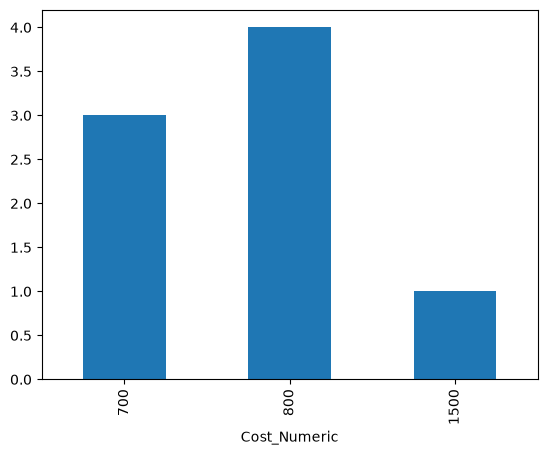

In [71]:
df["Cost_Numeric"].value_counts().sort_index().plot(kind="bar")

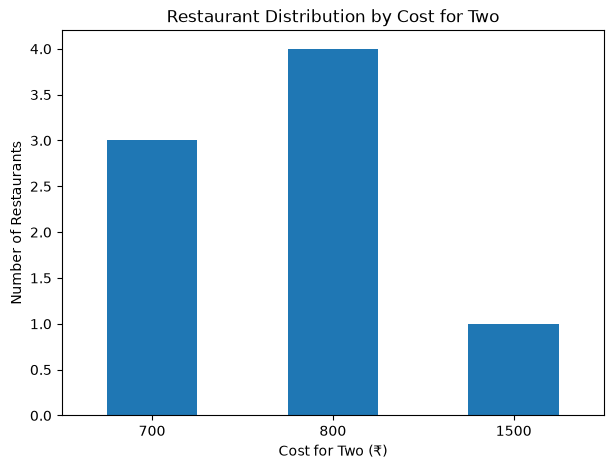

In [72]:
plt.figure(figsize=(7,5))

df["Cost_Numeric"].value_counts().sort_index().plot(kind="bar")

plt.title("Restaurant Distribution by Cost for Two")
plt.xlabel("Cost for Two (₹)")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=0)

plt.show()

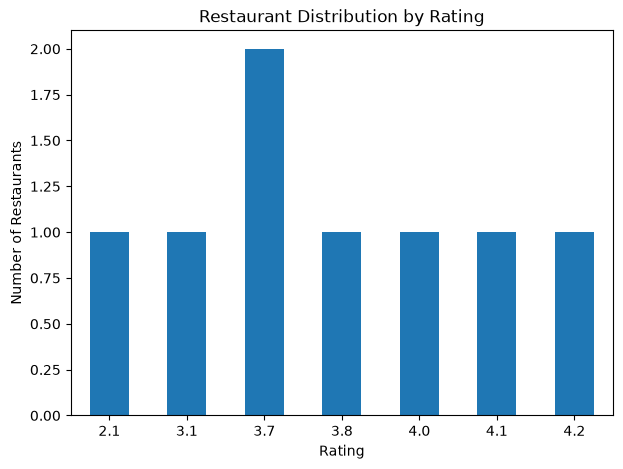

In [73]:
plt.figure(figsize=(7,5))

df["Rating"].value_counts().sort_index().plot(kind="bar")

plt.title("Restaurant Distribution by Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=0)

plt.show()

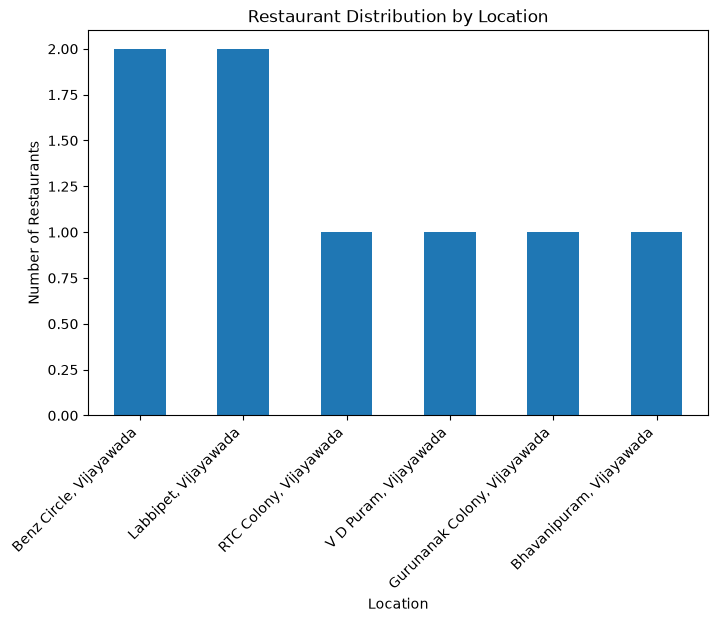

In [74]:
plt.figure(figsize=(8,5))

df["Location"].value_counts().plot(kind="bar")

plt.title("Restaurant Distribution by Location")
plt.xlabel("Location")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45, ha="right")

plt.show()

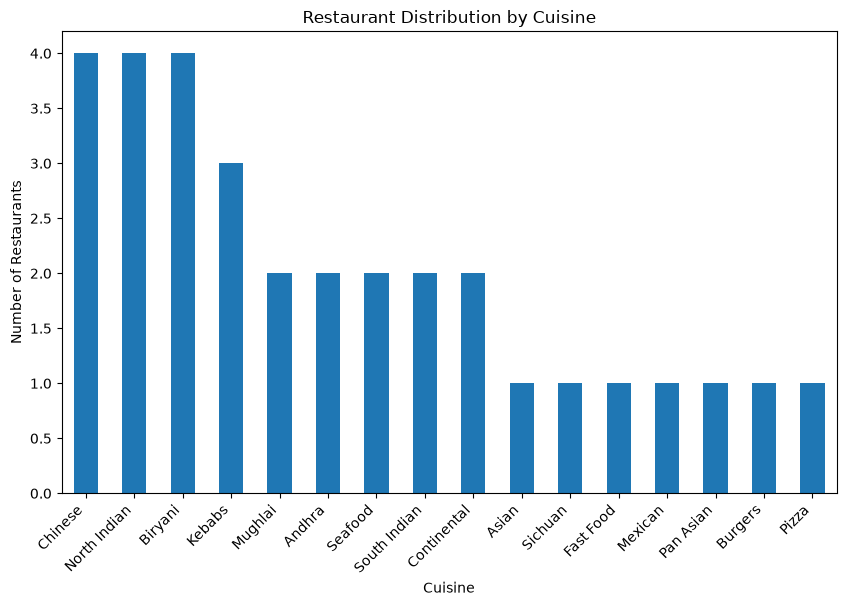

In [75]:
plt.figure(figsize=(10,6))

cuisine_expanded.value_counts().plot(kind="bar")

plt.title("Restaurant Distribution by Cuisine")
plt.xlabel("Cuisine")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45, ha="right")

plt.show()

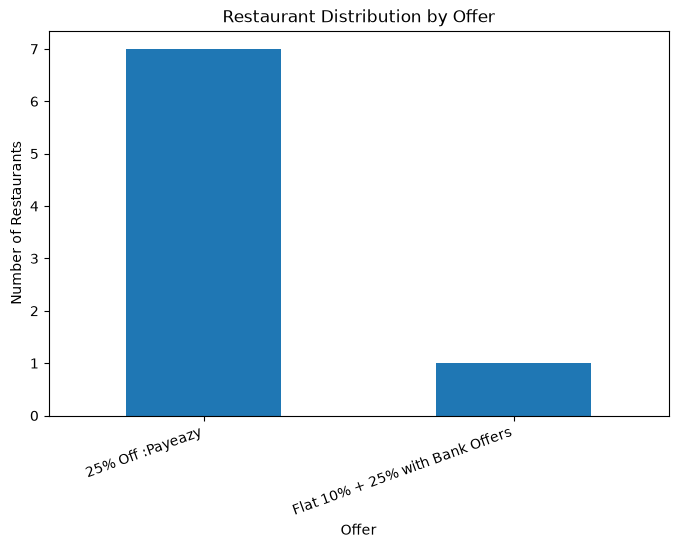

In [76]:
plt.figure(figsize=(8,5))

df["Offer"].value_counts().plot(kind="bar")

plt.title("Restaurant Distribution by Offer")
plt.xlabel("Offer")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=20, ha="right")

plt.show()

In [77]:
df[["Name", "Rating", "Cost_Numeric"]].sort_values("Rating", ascending=False)

,Name,Rating,Cost_Numeric
2,Swagramam Restaurant,4.2,700
6,Cicely Cafe,4.1,700
7,RR Durbar,4.0,800
5,Thrayam Fine Dining Restaurant,3.8,800
0,United Food Palace,3.7,800
3,Sattvik Soul,3.7,800
1,Amma Aathidyam,3.1,700
4,Patthar Ka Barbeque,2.1,1500


In [78]:
df["Rating"].corr(df["Cost_Numeric"])

np.float64(-0.8565183784556929)

In [79]:
df.groupby("Cost_Numeric")["Rating"].mean()

Cost_Numeric
700     3.8
800     3.8
1500    2.1
Name: Rating, dtype: float64

In [80]:
df["Location"].value_counts().sort_values(ascending=False)

Location
Benz Circle, Vijayawada         2
Labbipet, Vijayawada            2
RTC Colony, Vijayawada          1
V D Puram, Vijayawada           1
Gurunanak Colony, Vijayawada    1
Bhavanipuram, Vijayawada        1
Name: count, dtype: int64

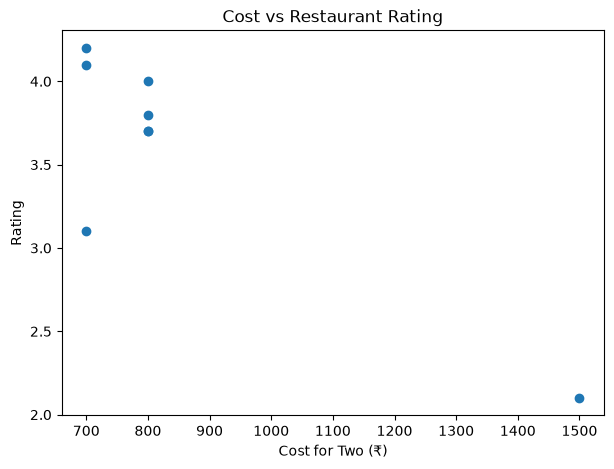

In [81]:
plt.figure(figsize=(7,5))

plt.scatter(df["Cost_Numeric"], df["Rating"])

plt.title("Cost vs Restaurant Rating")
plt.xlabel("Cost for Two (₹)")
plt.ylabel("Rating")

plt.show()

In [82]:
df[["Name", "Rating", "Cost_Numeric"]].sort_values(
    ["Rating", "Cost_Numeric"],
    ascending=[False, True]
)

,Name,Rating,Cost_Numeric
2,Swagramam Restaurant,4.2,700
6,Cicely Cafe,4.1,700
7,RR Durbar,4.0,800
5,Thrayam Fine Dining Restaurant,3.8,800
0,United Food Palace,3.7,800
3,Sattvik Soul,3.7,800
1,Amma Aathidyam,3.1,700
4,Patthar Ka Barbeque,2.1,1500


In [83]:
cuisine_df = df[["Name", "Rating", "Cuisine"]].copy()

In [84]:
links = soup.select("a[href]")

In [85]:
[(a.get_text(strip=True), a.get("href")) for a in links if a.get_text(strip=True).isdigit()]

[('2', 'https://www.eazydiner.com/vijayawada/restaurants?page=2'),
 ('3', 'https://www.eazydiner.com/vijayawada/restaurants?page=3'),
 ('4', 'https://www.eazydiner.com/vijayawada/restaurants?page=4'),
 ('5', 'https://www.eazydiner.com/vijayawada/restaurants?page=5'),
 ('6', 'https://www.eazydiner.com/vijayawada/restaurants?page=6'),
 ('7', 'https://www.eazydiner.com/vijayawada/restaurants?page=7'),
 ('8', 'https://www.eazydiner.com/vijayawada/restaurants?page=8'),
 ('25', 'https://www.eazydiner.com/vijayawada/restaurants?page=25')]

In [86]:
page_urls = [
    f"https://www.eazydiner.com/vijayawada/restaurants?page={page}"
    for page in range(1, 26)
]

In [87]:
all_restaurants = []

for page_url in page_urls:
    page_response = requests.get(page_url)
    page_soup = BeautifulSoup(page_response.text, "html.parser")
    
    page_restaurants = page_soup.select('a[aria-label]')
    all_restaurants.extend(page_restaurants)

print(len(all_restaurants))

200


In [88]:
restaurant_names = [restaurant.get("aria-label") for restaurant in all_restaurants]

print(len(restaurant_names))
print(len(set(restaurant_names)))

200
198


In [89]:
duplicates = [
    name for name in restaurant_names
    if restaurant_names.count(name) > 1
]

print(set(duplicates))

{'Sri Lakshmi Mourya Restaurant', 'Sweet Magic'}


In [90]:
unique_restaurants = list({
    restaurant.get("aria-label"): restaurant
    for restaurant in all_restaurants
}.values())

print(len(unique_restaurants))

198


In [92]:
missing_h3 = [
    restaurant for restaurant in unique_restaurants
    if restaurant.find("h3") is None
]

print(len(missing_h3))

198


In [93]:
unique_cards = [restaurant.parent for restaurant in unique_restaurants]

print(len(unique_cards))

198


In [94]:
names = [card.find("h3").get_text(strip=True) for card in unique_cards]

print(len(names))

198


In [96]:
missing_location = [
    card for card in unique_cards
    if card.find("div", class_="font-14 grey-text") is None
]

print(len(missing_location))

198


In [97]:
id="p9q2km"
[(div.get("class"), div.get_text(strip=True))
 for div in unique_cards[0].find_all("div")
 if "Benz Circle" in div.get_text()]

[(['relative', 'pointer'],
  '%25% Off :PayeazyEatOutUnited Food PalaceBenz Circle, VijayawadaChinese, Mughlai, North Indian, Kebabs, Andhra, Biryani₹800 for two3.7'),
 (['flex',
   'align-v-start',
   'flex-between',
   'padding-t-15',
   'padding-b-15',
   'margin-t-12',
   'relative',
   'full-width'],
  'United Food PalaceBenz Circle, VijayawadaChinese, Mughlai, North Indian, Kebabs, Andhra, Biryani₹800 for two3.7'),
 (['flex',
   'flex-column',
   'align-v-start',
   'gap_3',
   'relative',
   'flex-1',
   'max-w-80'],
  'United Food PalaceBenz Circle, VijayawadaChinese, Mughlai, North Indian, Kebabs, Andhra, Biryani₹800 for two'),
 (['flex', 'flex-column', 'align-v-start', 'gap_5', 'relative', 'full-width'],
  'Benz Circle, VijayawadaChinese, Mughlai, North Indian, Kebabs, Andhra, Biryani₹800 for two'),
 (['flex', 'align-v-center', 'gap_5', 'padding', 'relative'],
  'Benz Circle, Vijayawada'),
 (['relative', 'font-16', 'grey', 'ellipsis', 'listing-module__chvBCG__lh_18'],
  'Benz

In [98]:
location = unique_cards[0].find(
    "div",
    class_="listing-module__chvBCG__lh_18"
).get_text(strip=True)

print(location)

Benz Circle, Vijayawada


In [99]:
locations = [
    card.find(
        "div",
        class_="listing-module__chvBCG__lh_18"
    ).get_text(strip=True)
    for card in unique_cards
]

print(len(locations))

198


In [101]:
[
    (div.get("class"), div.get_text(strip=True))
    for div in unique_cards[0].find_all("div")
    if "Chinese" in div.get_text(strip=True)
]

[(['relative', 'pointer'],
  '%25% Off :PayeazyEatOutUnited Food PalaceBenz Circle, VijayawadaChinese, Mughlai, North Indian, Kebabs, Andhra, Biryani₹800 for two3.7'),
 (['flex',
   'align-v-start',
   'flex-between',
   'padding-t-15',
   'padding-b-15',
   'margin-t-12',
   'relative',
   'full-width'],
  'United Food PalaceBenz Circle, VijayawadaChinese, Mughlai, North Indian, Kebabs, Andhra, Biryani₹800 for two3.7'),
 (['flex',
   'flex-column',
   'align-v-start',
   'gap_3',
   'relative',
   'flex-1',
   'max-w-80'],
  'United Food PalaceBenz Circle, VijayawadaChinese, Mughlai, North Indian, Kebabs, Andhra, Biryani₹800 for two'),
 (['flex', 'flex-column', 'align-v-start', 'gap_5', 'relative', 'full-width'],
  'Benz Circle, VijayawadaChinese, Mughlai, North Indian, Kebabs, Andhra, Biryani₹800 for two'),
 (['flex', 'align-v-center', 'gap_5', 'relative'],
  'Chinese, Mughlai, North Indian, Kebabs, Andhra, Biryani₹800 for two'),
 (['relative', 'font-16', 'grey', 'ellipsis', 'listing

In [102]:
cuisines = [
    card.find_all(
        "div",
        class_="listing-module__chvBCG__lh_18"
    )[1].get_text(strip=True)
    for card in unique_cards
]

print(len(cuisines))

198


In [103]:
cost_elements = [
    card.find(string=lambda text: text and "for two" in text)
    for card in unique_cards
]

print(len(cost_elements))

198


In [104]:
costs = [element.strip() for element in cost_elements]

print(len(costs))
print(costs[:5])

198
['₹800 for two', '₹700 for two', '₹700 for two', '₹800 for two', '₹1500 for two']


In [105]:
rating_elements = unique_cards[0].find_all("text")

print(len(rating_elements))
print([element.get_text(strip=True) for element in rating_elements])

2
['%', '3.7']


In [106]:
ratings = [
    card.find_all("text")[1].get_text(strip=True)
    for card in unique_cards
]

print(len(ratings))
print(ratings[:5])

198
['3.7', '3.1', '4.2', '3.7', '2.1']


In [107]:
offer_element = unique_cards[0].find(
    "div",
    class_="relative font-16 bold white nowrap ellipsis"
)

print(offer_element.get_text(strip=True))

25% Off :Payeazy


In [108]:
offers = [
    card.find(
        "div",
        class_="relative font-16 bold white nowrap ellipsis"
    ).get_text(strip=True)
    for card in unique_cards
]

print(len(offers))
print(offers[:5])

198
['25% Off :Payeazy', '25% Off :Payeazy', '25% Off :Payeazy', '25% Off :Payeazy', 'Flat 10% + 25% with Bank Offers']


In [109]:
df = pd.DataFrame({
    "Name": names,
    "Location": locations,
    "Cuisine": cuisines,
    "Cost": costs,
    "Rating": ratings,
    "Offer": offers
})

df.shape


(198, 6)

In [110]:
cost_numbers = df["Cost"].apply(
    lambda x: re.findall(r"\d+", x)[0]
)

cost_numbers = cost_numbers.astype(int)

df["Cost_Numeric"] = cost_numbers

In [111]:
df["Rating"] = df["Rating"].astype(float)

In [112]:
df.dtypes

Name                str
Location            str
Cuisine             str
Cost                str
Rating          float64
Offer               str
Cost_Numeric      int64
dtype: object

In [113]:
df.isnull().sum()

Name            0
Location        0
Cuisine         0
Cost            0
Rating          0
Offer           0
Cost_Numeric    0
dtype: int64

In [114]:
df.duplicated().sum()

np.int64(0)

In [115]:
df.describe()

,Rating,Cost_Numeric
count,198.000000,198.000000
mean,3.841414,777.272727
std,0.887249,389.830936
min,1.000000,200.000000
25%,3.800000,512.500000
50%,4.000000,700.000000
75%,4.100000,800.000000
max,5.000000,2000.000000


In [116]:
cuisine_expanded = df["Cuisine"].str.split(", ").explode()

cuisine_expanded.value_counts().head(10)

Cuisine
North Indian    84
Chinese         78
Biryani         71
South Indian    43
Andhra          31
Desserts        28
Fast Food       26
Seafood         21
Continental     20
Mughlai         16
Name: count, dtype: int64

In [117]:
df["Cost_Numeric"].value_counts().sort_index()

Cost_Numeric
200      4
300      4
400     21
500     21
550      1
600     40
700     24
750      1
800     36
900      5
1000    12
1050     1
1100     2
1200     3
1400     3
1500     8
1600     1
1700     1
1800     3
1850     1
2000     6
Name: count, dtype: int64

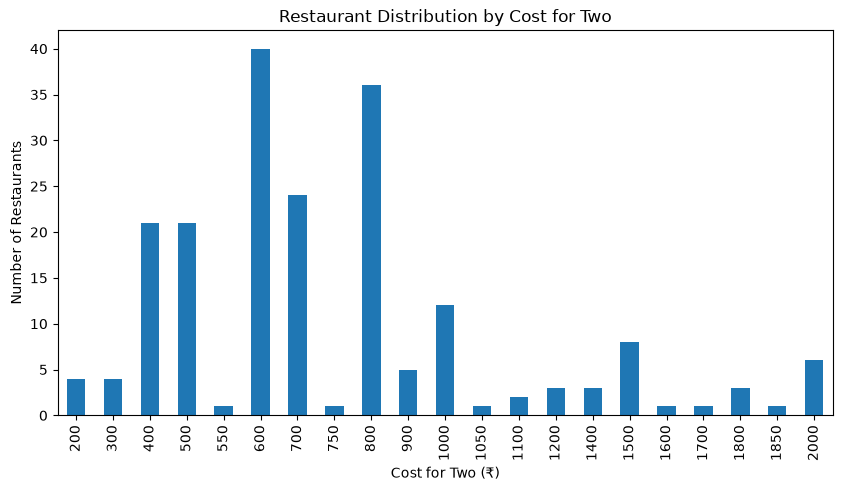

In [118]:
df["Cost_Numeric"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(10, 5),
    title="Restaurant Distribution by Cost for Two"
)

plt.xlabel("Cost for Two (₹)")
plt.ylabel("Number of Restaurants")
plt.show()

In [119]:
df["Rating"].value_counts().sort_index()

Rating
1.0    12
1.9     1
2.0     1
2.1     1
2.6     1
2.7     1
3.0     5
3.1     3
3.3     3
3.4     2
3.5     2
3.6     5
3.7     5
3.8     9
3.9     5
4.0    91
4.1     4
4.2     7
4.3     6
4.4     1
4.5     5
4.6     4
4.7     5
4.8     1
4.9     1
5.0    17
Name: count, dtype: int64

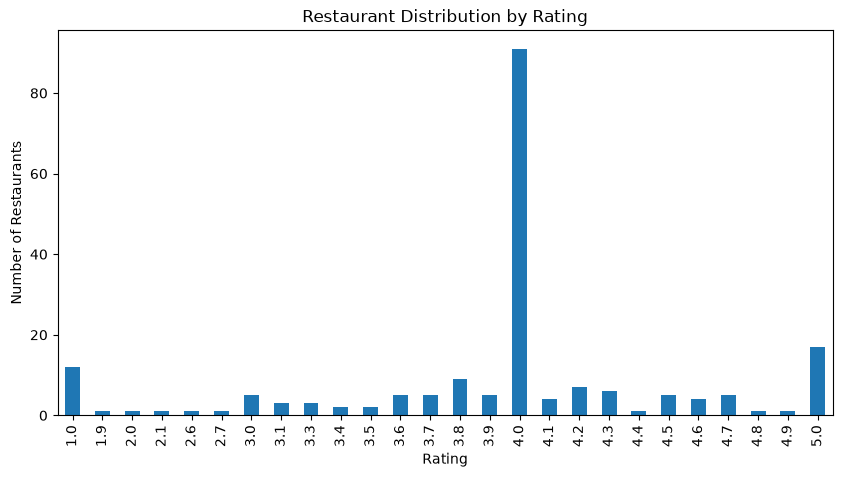

In [120]:
df["Rating"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(10, 5),
    title="Restaurant Distribution by Rating"
)

plt.xlabel("Rating")
plt.ylabel("Number of Restaurants")
plt.show()

In [121]:
df["Location"].value_counts().head(10)

Location
Gurunanak Colony, Vijayawada    18
Benz Circle, Vijayawada         17
Labbipet, Vijayawada            13
Kanuru, Vijayawada              10
Mangalagiri, Vijayawada          9
Tadepalle, Vijayawada            8
Bhavanipuram, Vijayawada         7
Krishna Lanka, Vijayawada        7
Poranki, Vijayawada              6
Patamata, Vijayawada             5
Name: count, dtype: int64

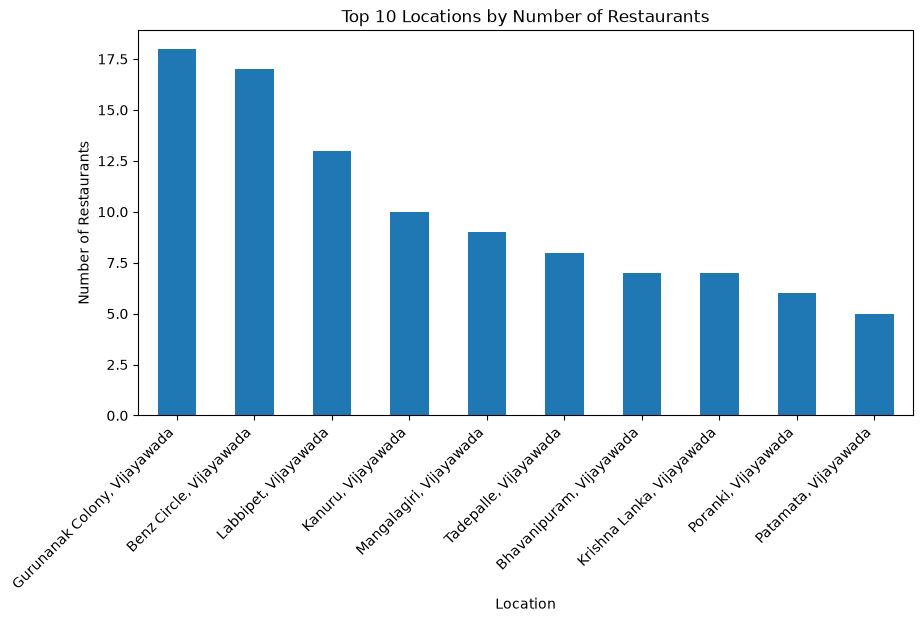

In [122]:
df["Location"].value_counts().head(10).plot(
    kind="bar",
    figsize=(10, 5),
    title="Top 10 Locations by Number of Restaurants"
)

plt.xlabel("Location")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45, ha="right")
plt.show()

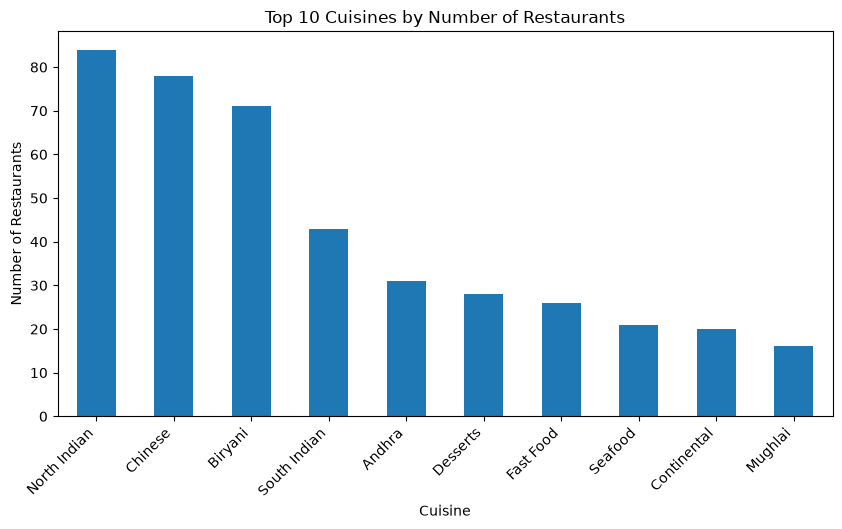

In [123]:
cuisine_expanded.value_counts().head(10).plot(
    kind="bar",
    figsize=(10, 5),
    title="Top 10 Cuisines by Number of Restaurants"
)

plt.xlabel("Cuisine")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45, ha="right")
plt.show()

In [124]:
df["Rating"].corr(df["Cost_Numeric"])

np.float64(-0.1347804193368561)

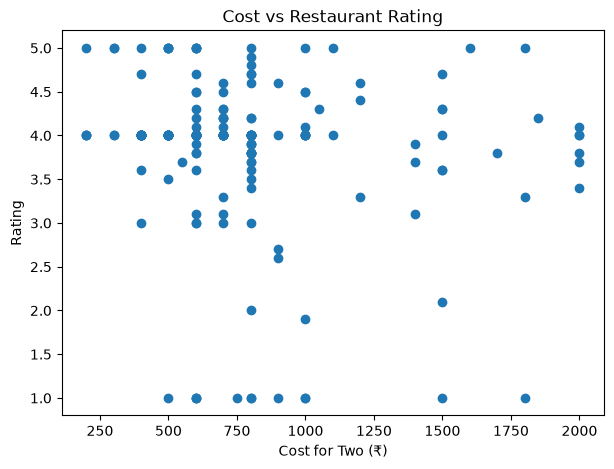

In [125]:
plt.figure(figsize=(7, 5))

plt.scatter(df["Cost_Numeric"], df["Rating"])

plt.title("Cost vs Restaurant Rating")
plt.xlabel("Cost for Two (₹)")
plt.ylabel("Rating")

plt.show()


Scraping Vijayawada...
Total pages found: 25
Page 1/25 -> 8 restaurants
Page 2/25 -> 8 restaurants
Page 3/25 -> 8 restaurants
Page 4/25 -> 8 restaurants
Page 5/25 -> 8 restaurants
Page 6/25 -> 8 restaurants
Page 7/25 -> 8 restaurants
Page 8/25 -> 8 restaurants
Page 9/25 -> 8 restaurants
Page 10/25 -> 8 restaurants
Page 11/25 -> 8 restaurants
Page 12/25 -> 8 restaurants
Page 13/25 -> 8 restaurants
Page 14/25 -> 8 restaurants
Page 15/25 -> 8 restaurants
Page 16/25 -> 8 restaurants
Page 17/25 -> 8 restaurants
Page 18/25 -> 8 restaurants
Page 19/25 -> 8 restaurants
Page 20/25 -> 8 restaurants
Page 21/25 -> 8 restaurants
Page 22/25 -> 8 restaurants
Page 23/25 -> 8 restaurants
Page 24/25 -> 8 restaurants
Page 25/25 -> 8 restaurants

Scraping Hyderabad...
Total pages found: 122
Page 1/122 -> 8 restaurants
Page 2/122 -> 8 restaurants
Page 3/122 -> 8 restaurants
Page 4/122 -> 8 restaurants
Page 5/122 -> 8 restaurants
Page 6/122 -> 8 restaurants
Page 7/122 -> 8 restaurants
Page 8/122 -> 8 resta

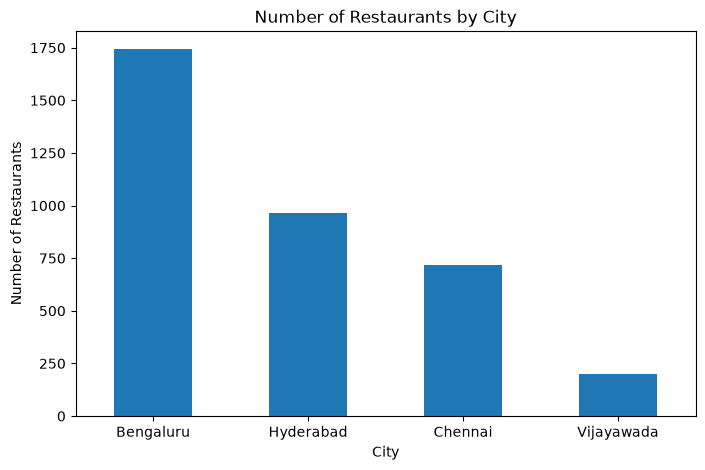

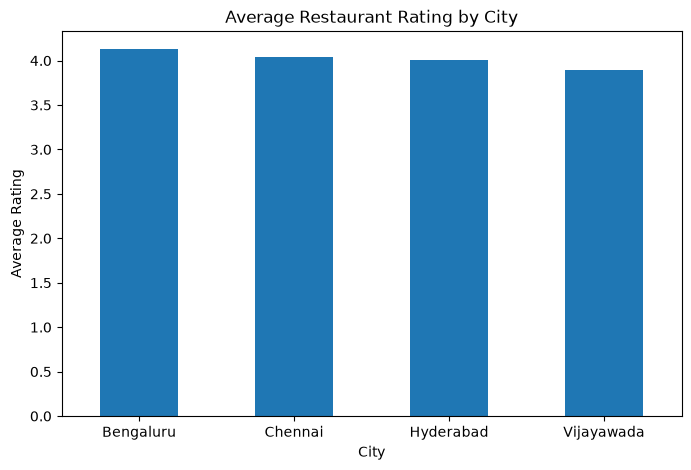

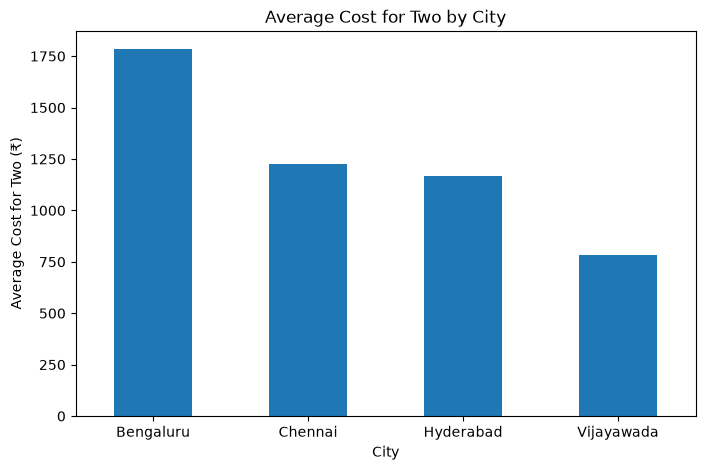

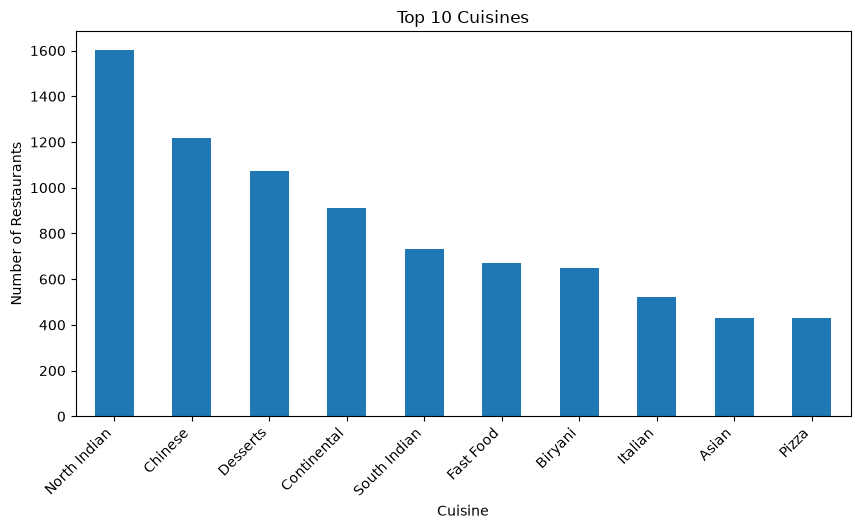

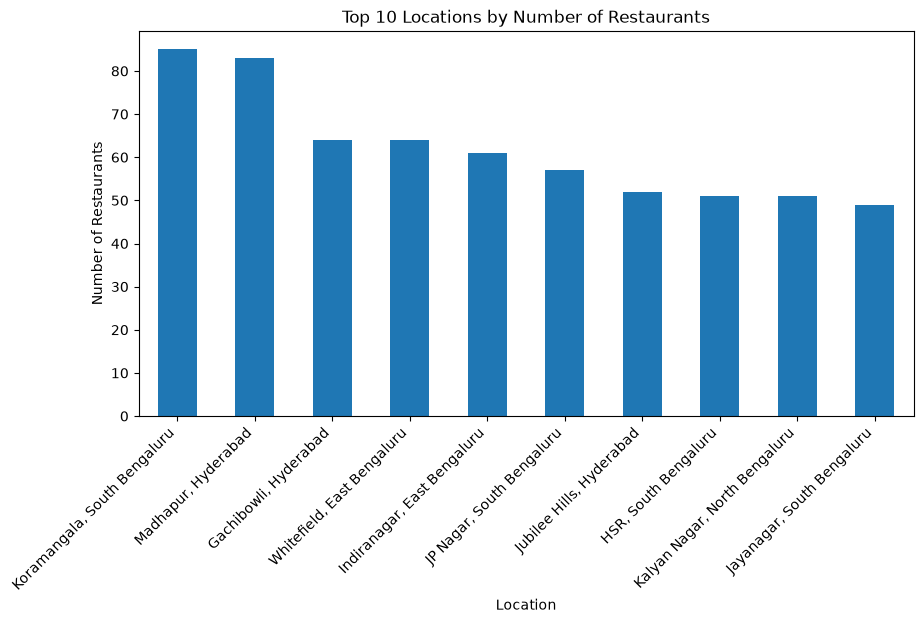

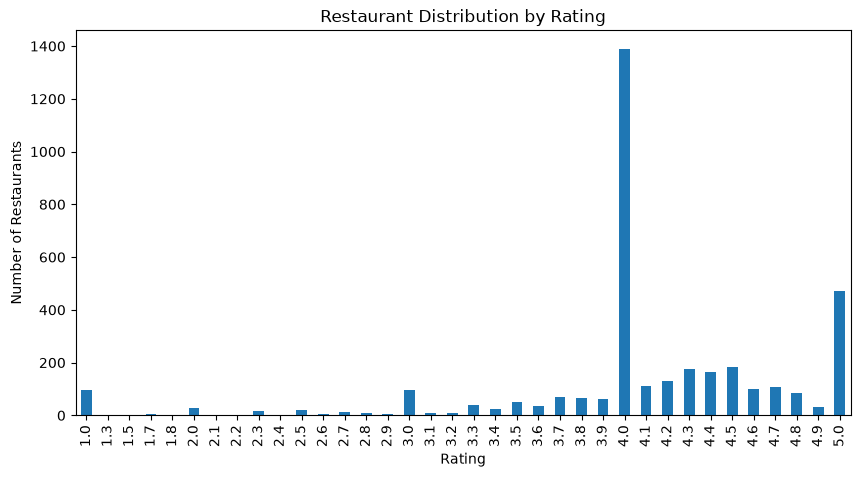

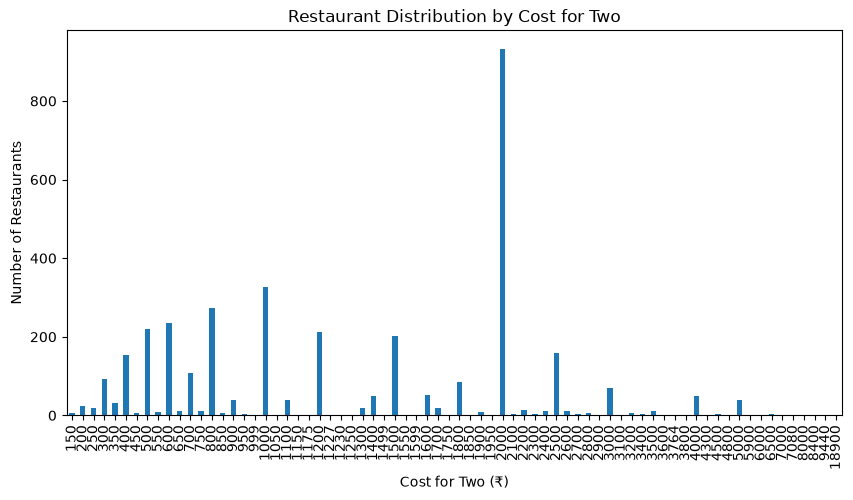

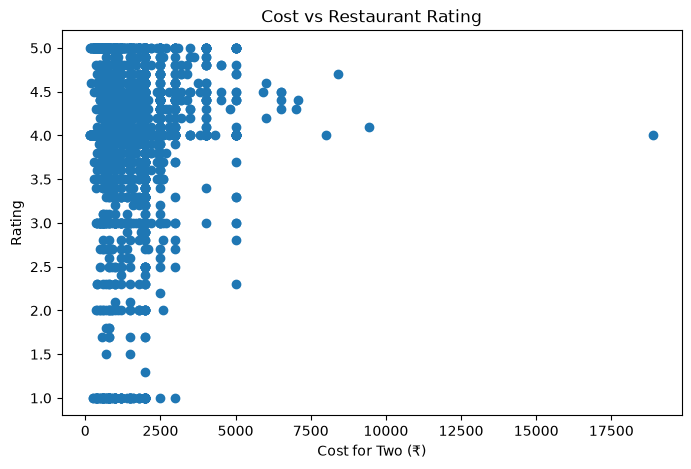


FINAL CSV SAVED SUCCESSFULLY
File: eazydiner_multi_city_restaurants.csv


In [126]:
# ============================================================
# EAZYDINER RESTAURANT ANALYSIS - MULTI CITY
# COMPLETE SCRAPING + CLEANING + EDA + VISUALIZATION
# ============================================================

import requests
from bs4 import BeautifulSoup
import pandas as pd
import re
import matplotlib.pyplot as plt
from urllib.parse import urlparse, parse_qs, urlencode, urlunparse


# ============================================================
# 1. CITY CONFIGURATION
# ============================================================

cities = {
    "Vijayawada": "https://www.eazydiner.com/vijayawada/restaurants",
    "Hyderabad": "https://www.eazydiner.com/hyderabad/restaurants",
    "Bengaluru": "https://www.eazydiner.com/bengaluru/restaurants",
    "Chennai": "https://www.eazydiner.com/chennai/restaurants"
}


# ============================================================
# 2. REQUEST SESSION
# ============================================================

session = requests.Session()

session.headers.update({
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/154.0.0.0 Safari/537.36"
    )
})


# ============================================================
# 3. FUNCTION TO CREATE PAGE URL
# ============================================================

def create_page_url(base_url, page_number):

    parsed_url = urlparse(base_url)

    query = parse_qs(parsed_url.query)

    query["page"] = [str(page_number)]

    new_query = urlencode(query, doseq=True)

    new_url = urlunparse((
        parsed_url.scheme,
        parsed_url.netloc,
        parsed_url.path,
        parsed_url.params,
        new_query,
        parsed_url.fragment
    ))

    return new_url


# ============================================================
# 4. FUNCTION TO FIND LAST PAGE
# ============================================================

def get_page_urls(base_url):

    response = session.get(base_url, timeout=30)

    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    page_numbers = []

    for a in soup.select("a[href]"):

        href = a.get("href")

        if not href:
            continue

        parsed_url = urlparse(href)

        query = parse_qs(parsed_url.query)

        if "page" in query:

            try:

                page_number = int(query["page"][0])

                page_numbers.append(page_number)

            except:

                pass

    if page_numbers:

        last_page = max(page_numbers)

    else:

        last_page = 1

    page_urls = [base_url]

    for page in range(2, last_page + 1):

        page_urls.append(
            create_page_url(base_url, page)
        )

    return page_urls


# ============================================================
# 5. FUNCTION TO EXTRACT DATA FROM ONE PAGE
# ============================================================

def extract_page_data(page_url, city):

    response = session.get(page_url, timeout=30)

    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    restaurants = soup.select('a[aria-label]')

    page_data = []


    for restaurant in restaurants:

        card = restaurant.parent


        # ----------------------------------------------------
        # NAME
        # ----------------------------------------------------

        name_element = card.find("h3")

        if name_element is None:
            continue

        name = name_element.get_text(strip=True)


        # ----------------------------------------------------
        # LOCATION + CUISINE
        # ----------------------------------------------------

        info_elements = card.find_all(
            "div",
            class_="listing-module__chvBCG__lh_18"
        )

        location = ""
        cuisine = ""

        if len(info_elements) >= 1:

            location = info_elements[0].get_text(
                strip=True
            )

        if len(info_elements) >= 2:

            cuisine = info_elements[1].get_text(
                strip=True
            )


        # ----------------------------------------------------
        # COST
        # ----------------------------------------------------

        cost_element = card.find(
            string=lambda text:
            text and "for two" in text
        )

        cost = ""

        if cost_element:

            cost = cost_element.strip()


        # ----------------------------------------------------
        # RATING
        # ----------------------------------------------------

        rating = None

        text_elements = card.find_all("text")

        rating_values = []

        for element in text_elements:

            value = element.get_text(strip=True)

            if re.fullmatch(
                r"[1-5](?:\.\d)?",
                value
            ):

                rating_values.append(value)

        if rating_values:

            rating = rating_values[-1]


        # ----------------------------------------------------
        # OFFER
        # ----------------------------------------------------

        offer = ""

        offer_element = card.find(
            "div",
            class_="relative font-16 bold white nowrap ellipsis"
        )

        if offer_element:

            offer = offer_element.get_text(
                strip=True
            )


        # ----------------------------------------------------
        # STORE DATA
        # ----------------------------------------------------

        page_data.append({

            "City": city,

            "Name": name,

            "Location": location,

            "Cuisine": cuisine,

            "Cost": cost,

            "Rating": rating,

            "Offer": offer

        })


    return page_data


# ============================================================
# 6. SCRAPE ALL CITIES
# ============================================================

all_data = []


for city, base_url in cities.items():

    print("\n" + "=" * 60)

    print(f"Scraping {city}...")

    print("=" * 60)


    try:

        page_urls = get_page_urls(base_url)

        print(
            "Total pages found:",
            len(page_urls)
        )


        for page_number, page_url in enumerate(
            page_urls,
            start=1
        ):

            try:

                page_data = extract_page_data(
                    page_url,
                    city
                )

                all_data.extend(page_data)

                print(
                    f"Page {page_number}/{len(page_urls)} "
                    f"-> {len(page_data)} restaurants"
                )


            except Exception as e:

                print(
                    f"Page {page_number} failed"
                )

                print("Error:", e)


    except Exception as e:

        print(
            f"{city} failed"
        )

        print("Error:", e)


# ============================================================
# 7. CREATE DATAFRAME
# ============================================================

final_df = pd.DataFrame(all_data)


print("\n" + "=" * 60)

print(
    "Total scraped records:",
    len(final_df)
)

print("=" * 60)


# ============================================================
# 8. REMOVE DUPLICATES
# ============================================================

final_df = final_df.drop_duplicates(
    subset=[
        "City",
        "Name",
        "Location"
    ]
).reset_index(drop=True)


print(
    "After duplicate removal:",
    len(final_df)
)


# ============================================================
# 9. CLEAN COST USING REGULAR EXPRESSION
# ============================================================

final_df["Cost_Numeric"] = (
    final_df["Cost"]
    .str.extract(r"(\d+)")[0]
)


final_df["Cost_Numeric"] = pd.to_numeric(
    final_df["Cost_Numeric"],
    errors="coerce"
)


# ============================================================
# 10. CLEAN RATING
# ============================================================

final_df["Rating"] = pd.to_numeric(
    final_df["Rating"],
    errors="coerce"
)


# ============================================================
# 11. BASIC DATA CHECK
# ============================================================

print("\n" + "=" * 60)

print("DATAFRAME SHAPE")

print("=" * 60)

print(final_df.shape)


print("\nCOLUMNS")

print(final_df.columns.tolist())


print("\nMISSING VALUES")

print(final_df.isnull().sum())


print("\nDUPLICATE ROWS")

print(final_df.duplicated().sum())


# ============================================================
# 12. DATA TYPES
# ============================================================

print("\nDATA TYPES")

print(final_df.dtypes)


# ============================================================
# 13. CITY-WISE RESTAURANT COUNT
# ============================================================

city_counts = (
    final_df["City"]
    .value_counts()
)


print("\n" + "=" * 60)

print("RESTAURANTS BY CITY")

print("=" * 60)

print(city_counts)


# ============================================================
# 14. CITY-WISE AVERAGE RATING
# ============================================================

city_rating = (
    final_df
    .groupby("City")["Rating"]
    .mean()
    .sort_values(
        ascending=False
    )
)


print("\n" + "=" * 60)

print("AVERAGE RATING BY CITY")

print("=" * 60)

print(city_rating)


# ============================================================
# 15. CITY-WISE AVERAGE COST
# ============================================================

city_cost = (
    final_df
    .groupby("City")["Cost_Numeric"]
    .mean()
    .sort_values(
        ascending=False
    )
)


print("\n" + "=" * 60)

print("AVERAGE COST FOR TWO BY CITY")

print("=" * 60)

print(city_cost)


# ============================================================
# 16. TOP CUISINES OVERALL
# ============================================================

cuisine_expanded = (
    final_df["Cuisine"]
    .dropna()
    .str.split(", ")
    .explode()
)


top_cuisines = (
    cuisine_expanded
    .value_counts()
    .head(10)
)


print("\n" + "=" * 60)

print("TOP 10 CUISINES")

print("=" * 60)

print(top_cuisines)


# ============================================================
# 17. CITY-WISE CUISINE ANALYSIS
# ============================================================

city_cuisine = (
    final_df
    .assign(
        Cuisine=final_df["Cuisine"].str.split(", ")
    )
    .explode("Cuisine")
    .groupby(
        ["City", "Cuisine"]
    )
    .size()
    .reset_index(
        name="Restaurant_Count"
    )
    .sort_values(
        ["City", "Restaurant_Count"],
        ascending=[True, False]
    )
)


print("\n" + "=" * 60)

print("CITY-WISE CUISINE ANALYSIS")

print("=" * 60)

print(
    city_cuisine.head(30)
)


# ============================================================
# 18. RATING DISTRIBUTION
# ============================================================

rating_distribution = (
    final_df["Rating"]
    .value_counts()
    .sort_index()
)


print("\n" + "=" * 60)

print("RATING DISTRIBUTION")

print("=" * 60)

print(rating_distribution)


# ============================================================
# 19. COST DISTRIBUTION
# ============================================================

cost_distribution = (
    final_df["Cost_Numeric"]
    .value_counts()
    .sort_index()
)


print("\n" + "=" * 60)

print("COST DISTRIBUTION")

print("=" * 60)

print(cost_distribution)


# ============================================================
# 20. TOP LOCATIONS
# ============================================================

top_locations = (
    final_df["Location"]
    .value_counts()
    .head(10)
)


print("\n" + "=" * 60)

print("TOP 10 LOCATIONS")

print("=" * 60)

print(top_locations)


# ============================================================
# 21. COST VS RATING CORRELATION
# ============================================================

correlation = (
    final_df["Cost_Numeric"]
    .corr(
        final_df["Rating"]
    )
)


print("\n" + "=" * 60)

print("COST VS RATING CORRELATION")

print("=" * 60)

print(correlation)


# ============================================================
# 22. HIGHEST RATED RESTAURANTS
# ============================================================

highest_rated = (
    final_df[
        [
            "City",
            "Name",
            "Rating",
            "Cost_Numeric"
        ]
    ]
    .sort_values(
        "Rating",
        ascending=False
    )
    .head(10)
)


print("\n" + "=" * 60)

print("TOP 10 HIGHEST-RATED RESTAURANTS")

print("=" * 60)

print(highest_rated)


# ============================================================
# 23. LOWEST RATED RESTAURANTS
# ============================================================

lowest_rated = (
    final_df[
        [
            "City",
            "Name",
            "Rating",
            "Cost_Numeric"
        ]
    ]
    .sort_values(
        "Rating",
        ascending=True
    )
    .head(10)
)


print("\n" + "=" * 60)

print("10 LOWEST-RATED RESTAURANTS")

print("=" * 60)

print(lowest_rated)


# ============================================================
# 24. DESCRIPTIVE STATISTICS
# ============================================================

print("\n" + "=" * 60)

print("DESCRIPTIVE STATISTICS")

print("=" * 60)

print(
    final_df[
        [
            "Rating",
            "Cost_Numeric"
        ]
    ].describe()
)


# ============================================================
# 25. VISUALIZATION - RESTAURANTS BY CITY
# ============================================================

city_counts.plot(
    kind="bar",
    figsize=(8, 5),
    title="Number of Restaurants by City"
)

plt.xlabel("City")

plt.ylabel("Number of Restaurants")

plt.xticks(rotation=0)

plt.show()


# ============================================================
# 26. VISUALIZATION - AVERAGE RATING
# ============================================================

city_rating.plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Restaurant Rating by City"
)

plt.xlabel("City")

plt.ylabel("Average Rating")

plt.xticks(rotation=0)

plt.show()


# ============================================================
# 27. VISUALIZATION - AVERAGE COST
# ============================================================

city_cost.plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Cost for Two by City"
)

plt.xlabel("City")

plt.ylabel("Average Cost for Two (₹)")

plt.xticks(rotation=0)

plt.show()


# ============================================================
# 28. VISUALIZATION - TOP CUISINES
# ============================================================

top_cuisines.plot(
    kind="bar",
    figsize=(10, 5),
    title="Top 10 Cuisines"
)

plt.xlabel("Cuisine")

plt.ylabel("Number of Restaurants")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.show()


# ============================================================
# 29. VISUALIZATION - TOP LOCATIONS
# ============================================================

top_locations.plot(
    kind="bar",
    figsize=(10, 5),
    title="Top 10 Locations by Number of Restaurants"
)

plt.xlabel("Location")

plt.ylabel("Number of Restaurants")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.show()


# ============================================================
# 30. VISUALIZATION - RATING DISTRIBUTION
# ============================================================

rating_distribution.plot(
    kind="bar",
    figsize=(10, 5),
    title="Restaurant Distribution by Rating"
)

plt.xlabel("Rating")

plt.ylabel("Number of Restaurants")

plt.show()


# ============================================================
# 31. VISUALIZATION - COST DISTRIBUTION
# ============================================================

cost_distribution.plot(
    kind="bar",
    figsize=(10, 5),
    title="Restaurant Distribution by Cost for Two"
)

plt.xlabel("Cost for Two (₹)")

plt.ylabel("Number of Restaurants")

plt.show()


# ============================================================
# 32. VISUALIZATION - COST VS RATING
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    final_df["Cost_Numeric"],
    final_df["Rating"]
)

plt.title(
    "Cost vs Restaurant Rating"
)

plt.xlabel(
    "Cost for Two (₹)"
)

plt.ylabel(
    "Rating"
)

plt.show()


# ============================================================
# 33. SAVE FINAL DATASET
# ============================================================

final_df.to_csv(
    "eazydiner_multi_city_restaurants.csv",
    index=False
)


print("\n" + "=" * 60)

print(
    "FINAL CSV SAVED SUCCESSFULLY"
)

print(
    "File: eazydiner_multi_city_restaurants.csv"
)

print("=" * 60)

In [127]:
print("Shape:", final_df.shape)

print("\nRestaurants by City:")
print(final_df["City"].value_counts())

print("\nMissing Values:")
print(final_df.isnull().sum())

print("\nDuplicate Rows:")
print(final_df.duplicated().sum())

print("\nData Types:")
print(final_df.dtypes)

Shape: (3626, 8)

Restaurants by City:
City
Bengaluru     1742
Hyderabad      967
Chennai        717
Vijayawada     200
Name: count, dtype: int64

Missing Values:
City            0
Name            0
Location        0
Cuisine         0
Cost            0
Rating          4
Offer           0
Cost_Numeric    0
dtype: int64

Duplicate Rows:
0

Data Types:
City                str
Name                str
Location            str
Cuisine             str
Cost                str
Rating          float64
Offer               str
Cost_Numeric      int64
dtype: object


In [129]:
# ============================================================
# BUSINESS QUESTIONS - DATA ANALYSIS
# ============================================================

# 1. Which city has the highest number of restaurants?
print("1. Restaurant Count by City:")
print(final_df["City"].value_counts())


# 2. What is the average rating of restaurants in each city?
print("\n2. Average Rating by City:")
print(final_df.groupby("City")["Rating"].mean().sort_values(ascending=False))


# 3. What is the average cost for two in each city?
print("\n3. Average Cost for Two by City:")
print(final_df.groupby("City")["Cost_Numeric"].mean().sort_values(ascending=False))


# 4. Which cuisines are most common overall?
print("\n4. Top 10 Cuisines Overall:")
print(top_cuisines)


# 5. Which cuisines are most common in each city?
print("\n5. Top 5 Cuisines by City:")

top_cuisines_by_city = (
    final_df
    .assign(Cuisine=final_df["Cuisine"].str.split(", "))
    .explode("Cuisine")
    .groupby(["City", "Cuisine"])
    .size()
    .reset_index(name="Restaurant_Count")
    .sort_values(
        ["City", "Restaurant_Count"],
        ascending=[True, False]
    )
    .groupby("City")
    .head(5)
)

print(top_cuisines_by_city)


# 6. What is the relationship between cost and rating?
print("\n6. Cost vs Rating Correlation:")
print(
    final_df["Cost_Numeric"].corr(
        final_df["Rating"]
    )
)


# 7. Which locations have the highest number of restaurants?
print("\n7. Top 10 Restaurant Locations:")
print(top_locations)


# 8. What are the highest-rated restaurants?
print("\n8. Top 10 Highest-Rated Restaurants:")
print(highest_rated)


# 9. What are the lowest-rated restaurants?
print("\n9. 10 Lowest-Rated Restaurants:")
print(lowest_rated)


# 10. Overall descriptive statistics
print("\n10. Overall Statistics:")
print(
    final_df[
        ["Rating", "Cost_Numeric"]
    ].describe()
)

1. Restaurant Count by City:
City
Bengaluru     1742
Hyderabad      967
Chennai        717
Vijayawada     200
Name: count, dtype: int64

2. Average Rating by City:
City
Bengaluru     4.126207
Chennai       4.037063
Hyderabad     4.011686
Vijayawada    3.891000
Name: Rating, dtype: float64

3. Average Cost for Two by City:
City
Bengaluru     1782.904133
Chennai       1223.596932
Hyderabad     1169.260600
Vijayawada     781.750000
Name: Cost_Numeric, dtype: float64

4. Top 10 Cuisines Overall:
Cuisine
North Indian    1604
Chinese         1216
Desserts        1072
Continental      911
South Indian     731
Fast Food        670
Biryani          647
Italian          520
Asian            431
Pizza            430
Name: count, dtype: int64

5. Top 5 Cuisines by City:
           City       Cuisine  Restaurant_Count
84    Bengaluru  North Indian               800
27    Bengaluru       Chinese               575
33    Bengaluru      Desserts               532
32    Bengaluru   Continental          

# Business Questions and Answers

## 1. Which city has the highest number of restaurants in the scraped dataset?

**Answer:** Bengaluru has the highest number of restaurant listings with 1,742 restaurants, followed by Hyderabad with 967, Chennai with 717, and Vijayawada with 200.

## 2. What is the average restaurant rating in each city?

**Answer:** Bengaluru has an average rating of 4.13, Chennai 4.04, Hyderabad 4.01, and Vijayawada 3.89.

## 3. Which city has the highest average cost for two people?

**Answer:** Bengaluru has the highest average cost for two at approximately ₹1,782.90. Chennai follows with ₹1,223.60, Hyderabad with ₹1,169.26, and Vijayawada with ₹781.75.

## 4. Which cuisines are most common across the four cities?

**Answer:** North Indian is the most common cuisine with 1,604 listings, followed by Chinese with 1,216 and Desserts with 1,072.

## 5. Which cuisines are most common in each city?

**Answer:** North Indian cuisine is the most common cuisine in all four cities in the scraped dataset. Chinese cuisine is also highly represented across the cities.

## 6. Is there a strong relationship between restaurant cost and rating?

**Answer:** The correlation between cost and rating is approximately 0.069, indicating a very weak positive linear relationship in the scraped dataset.

## 7. Which locations have the highest number of restaurant listings?

**Answer:** Koramangala, South Bengaluru has the highest number of listings with 85, followed by Madhapur, Hyderabad with 83 and Gachibowli, Hyderabad with 64.

## 8. What is the overall rating and cost distribution?

**Answer:** The average restaurant rating is approximately 4.07, while the average cost for two is approximately ₹1,453.44. The median cost for two is ₹1,200.

# Business Insights

1. Bengaluru has the highest number of restaurant listings in the scraped dataset, with 1,742 restaurants.

2. Bengaluru also has the highest average restaurant rating among the four cities, with an average rating of approximately 4.13.

3. Bengaluru has the highest average cost for two people at approximately ₹1,782.90, indicating a higher average price level in the scraped listings.

4. North Indian cuisine is the most commonly listed cuisine across the four cities, followed by Chinese and Desserts.

5. North Indian cuisine is the most frequently listed cuisine in each of the four cities.

6. Koramangala, South Bengaluru has the highest number of restaurant listings among the locations analyzed, followed by Madhapur and Gachibowli in Hyderabad.

7. The correlation between restaurant cost and rating is approximately 0.069, indicating that cost has very little linear relationship with restaurant rating in this dataset.

8. The overall average restaurant rating is approximately 4.07, while the median cost for two is ₹1,200.

9. The scraped dataset contains 3,626 restaurant listings across Bengaluru, Hyderabad, Chennai, and Vijayawada.

10. The analysis shows substantial variation in restaurant costs across the four cities, with Bengaluru having the highest average cost and Vijayawada having the lowest average cost among the scraped listings.

# Business Recommendations

1. Restaurants can use city-wise pricing information to understand the different price levels observed across the analyzed cities.

2. Restaurants can consider offering popular cuisines such as North Indian and Chinese, since these cuisines have a high number of listings in the scraped dataset.

3. Restaurant owners can analyze highly represented locations such as Koramangala, Madhapur, and Gachibowli to understand areas with a high concentration of restaurant listings.

4. Since the analysis shows a very weak relationship between cost and rating, restaurants should not rely only on higher pricing to improve customer ratings.

5. Restaurants can focus on maintaining service and food quality while keeping pricing appropriate for their target customers.

6. EazyDiner can use city-wise restaurant, cuisine, rating, and pricing data to provide more detailed information to users when comparing restaurants across different cities.

7. Restaurants with lower ratings can analyze the characteristics of highly rated listings and identify areas where customer experience may be improved.

8. Pricing and cuisine trends can be monitored periodically because restaurant listings, prices, ratings, and offers may change over time.